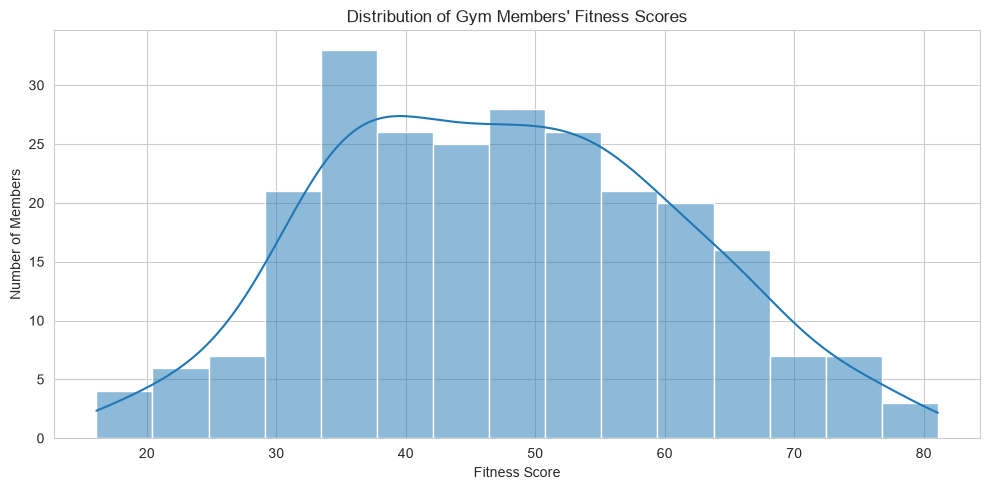

In [14]:
# Q1: Fitness Score Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Fitness_Score",
    bins=15,
    kde=True
)

plt.title("Distribution of Gym Members' Fitness Scores")

plt.xlabel("Fitness Score")

plt.ylabel("Number of Members")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q1_fitness_distribution.png",
    dpi=300
)

plt.show()

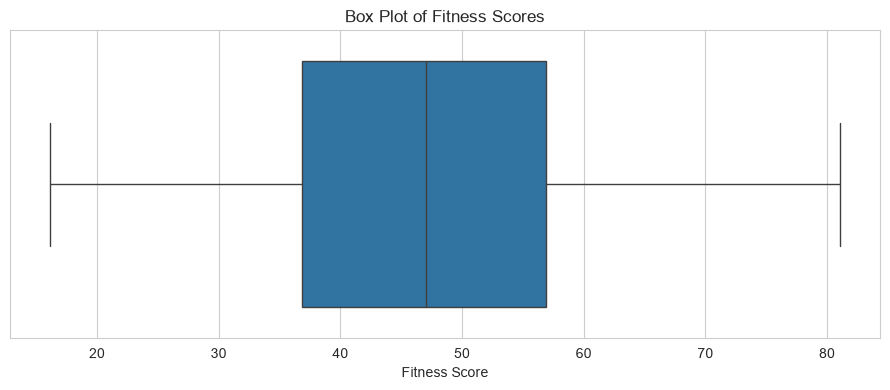

In [15]:
# Q1: Fitness Score Box Plot

plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df_clean["Fitness_Score"]
)

plt.title("Box Plot of Fitness Scores")

plt.xlabel("Fitness Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q1_fitness_boxplot.png",
    dpi=300
)

plt.show()

In [16]:
# Q2: Correlation Analysis

correlation_visits = df_clean[
    ["Visits_Per_Week", "Fitness_Score"]
].corr()

correlation_minutes = df_clean[
    ["Avg_Session_Minutes", "Fitness_Score"]
].corr()

print("Correlation between visits and fitness score")

display(correlation_visits)

print("Correlation between session minutes and fitness score")

display(correlation_minutes)


# Combined correlation table

correlation_table = df_clean[
    [
        "Visits_Per_Week",
        "Avg_Session_Minutes",
        "Fitness_Score"
    ]
].corr()

display(correlation_table)

Correlation between visits and fitness score


,Visits_Per_Week,Fitness_Score
Visits_Per_Week,1.000000,0.542063
Fitness_Score,0.542063,1.000000


Correlation between session minutes and fitness score


,Avg_Session_Minutes,Fitness_Score
Avg_Session_Minutes,1.000000,0.570249
Fitness_Score,0.570249,1.000000


,Visits_Per_Week,Avg_Session_Minutes,Fitness_Score
Visits_Per_Week,1.000000,0.101246,0.542063
Avg_Session_Minutes,0.101246,1.000000,0.570249
Fitness_Score,0.542063,0.570249,1.000000


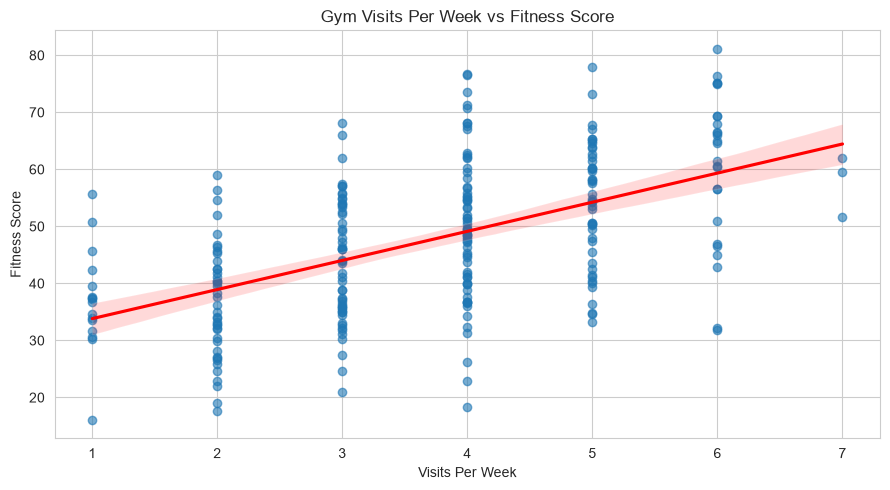

In [17]:
# Q2: Visits Per Week vs Fitness Score

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_clean,
    x="Visits_Per_Week",
    y="Fitness_Score",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Gym Visits Per Week vs Fitness Score")

plt.xlabel("Visits Per Week")

plt.ylabel("Fitness Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q2_visits_vs_fitness.png",
    dpi=300
)

plt.show()

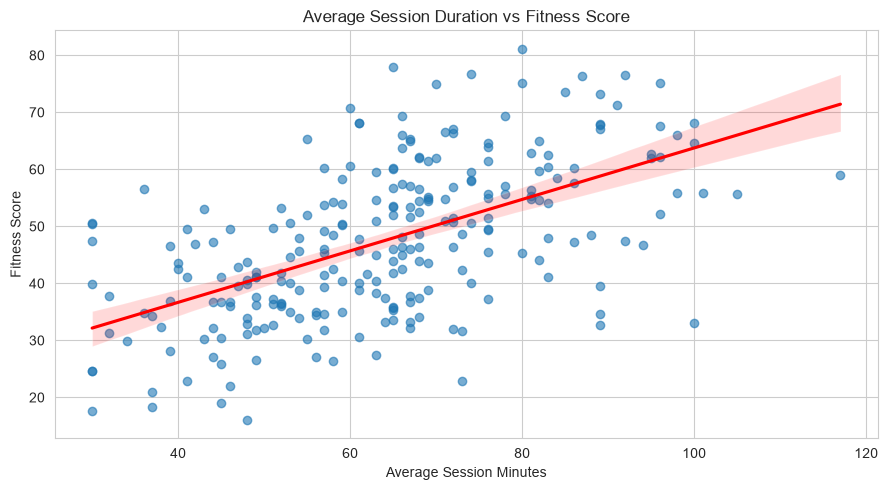

In [18]:
# Q2: Session Minutes vs Fitness Score

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_clean,
    x="Avg_Session_Minutes",
    y="Fitness_Score",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Average Session Duration vs Fitness Score")

plt.xlabel("Average Session Minutes")

plt.ylabel("Fitness Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q2_session_minutes_vs_fitness.png",
    dpi=300
)

plt.show()

In [19]:
# Q3: Fitness Score by Membership Type

membership_analysis = df_clean.groupby(
    "Membership_Type"
)["Fitness_Score"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print("FITNESS SCORE BY MEMBERSHIP TYPE")

display(membership_analysis)


# Fitness Score by City

city_analysis = df_clean.groupby(
    "City"
)["Fitness_Score"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print("FITNESS SCORE BY CITY")

display(city_analysis)


# Fitness Score by Gender

gender_analysis = df_clean.groupby(
    "Gender"
)["Fitness_Score"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print("FITNESS SCORE BY GENDER")

display(gender_analysis)


# Fitness Score by Workout Preference

workout_analysis = df_clean.groupby(
    "Workout_Preference"
)["Fitness_Score"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print("FITNESS SCORE BY WORKOUT PREFERENCE")

display(workout_analysis)

FITNESS SCORE BY MEMBERSHIP TYPE


,count,mean,median,std
Membership_Type,,,,
Basic,125,46.19,45.4,13.67
Premium,44,53.14,51.7,13.95
Standard,81,46.58,46.3,12.22


FITNESS SCORE BY CITY


,count,mean,median,std
City,,,,
Bengaluru,60,48.43,47.60,13.37
Delhi,78,47.96,47.65,12.47
Hyderabad,29,47.58,46.10,15.92
Mumbai,57,46.25,46.30,13.53
Pune,26,47.02,48.95,14.37


FITNESS SCORE BY GENDER


,count,mean,median,std
Gender,,,,
Female,98,48.19,47.60,13.64
Male,146,46.86,46.25,13.32
Other,6,53.47,57.20,14.87


FITNESS SCORE BY WORKOUT PREFERENCE


,count,mean,median,std
Workout_Preference,,,,
Cardio,97,48.22,47.9,13.65
CrossFit,29,49.92,48.4,13.83
Strength,61,46.33,46.9,14.31
Yoga,52,47.28,46.1,12.34
Zumba,11,43.25,41.2,11.81


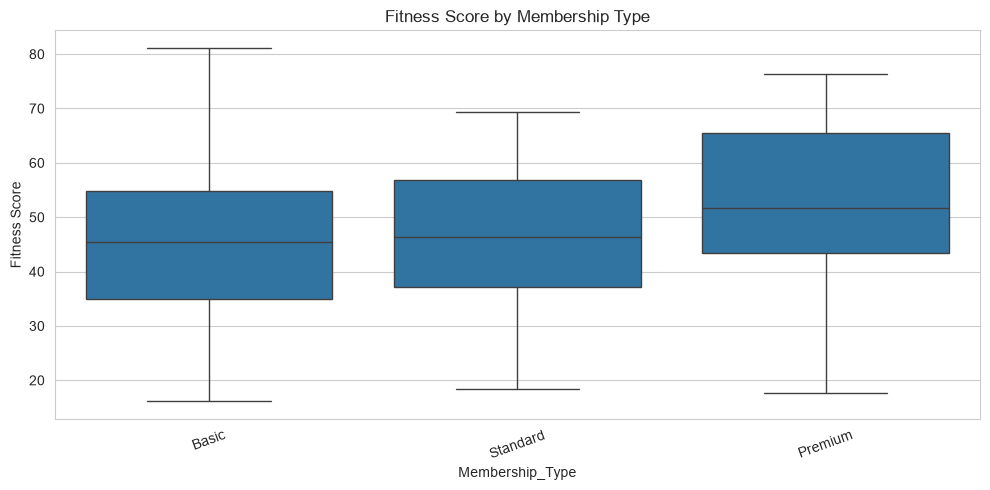

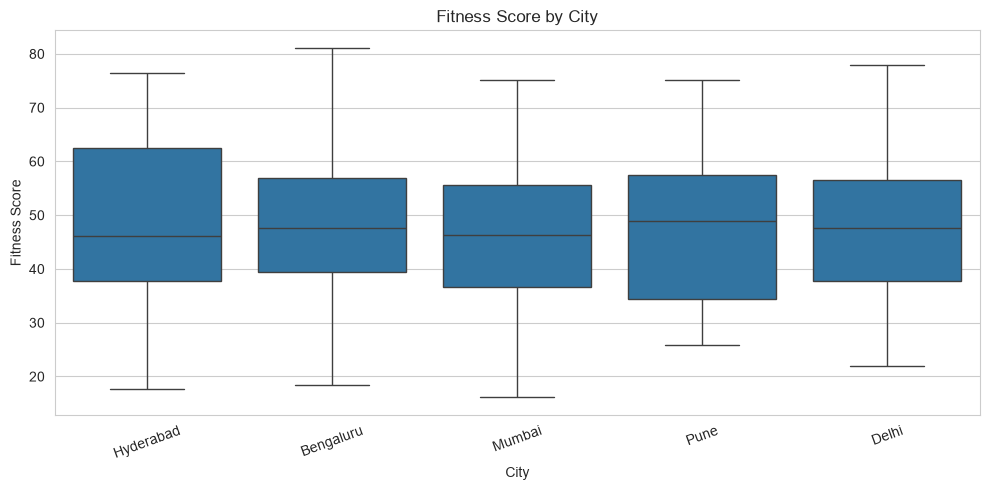

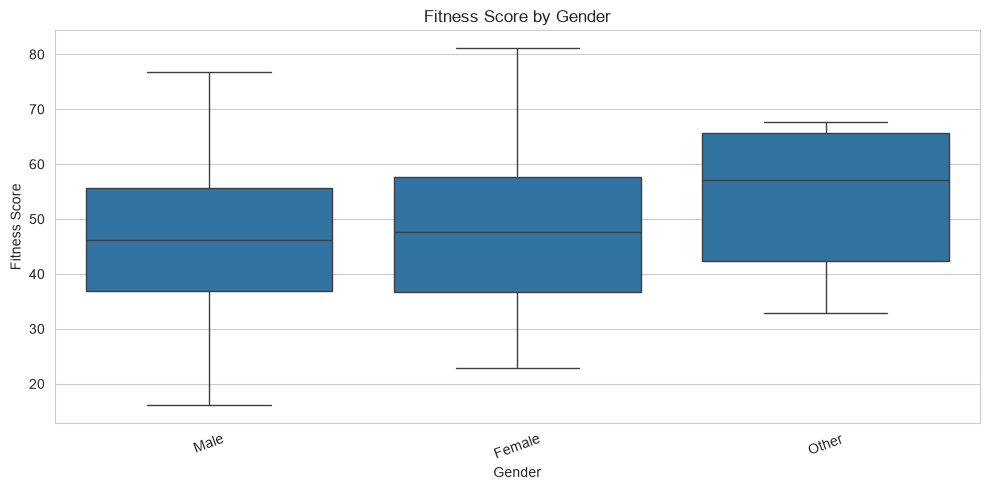

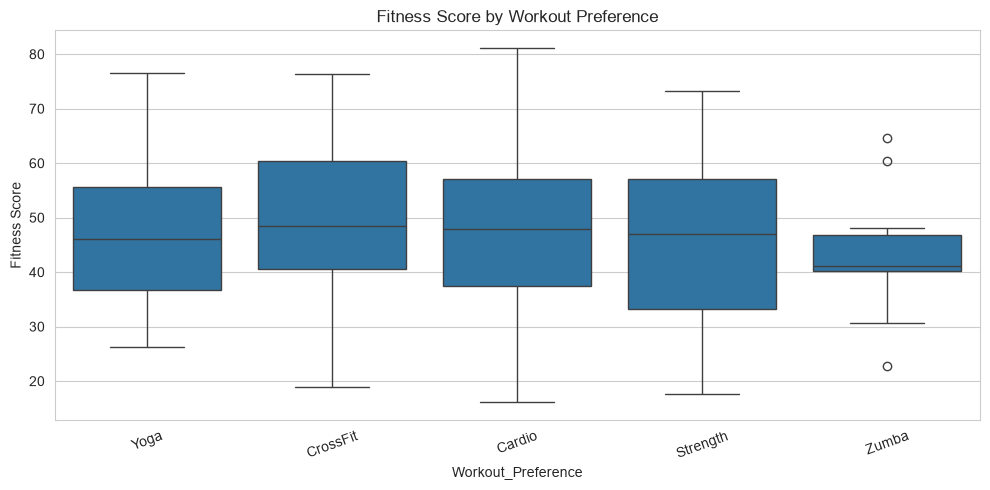

In [20]:
# Q3: Group-wise Fitness Score Comparison

group_columns = [
    "Membership_Type",
    "City",
    "Gender",
    "Workout_Preference"
]

titles = [
    "Fitness Score by Membership Type",
    "Fitness Score by City",
    "Fitness Score by Gender",
    "Fitness Score by Workout Preference"
]

for column, title in zip(group_columns, titles):

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df_clean,
        x=column,
        y="Fitness_Score"
    )

    plt.title(title)

    plt.xlabel(column)

    plt.ylabel("Fitness Score")

    plt.xticks(rotation=20)

    plt.tight_layout()

    filename = column.lower() + "_fitness_comparison.png"

    plt.savefig(
        PROJECT_ROOT / "images" / filename,
        dpi=300
    )

    plt.show()

### Answer to Question 3

Membership Type:
The highest average fitness score is observed in
__________ membership.

City:
The city with the highest average fitness score
is __________.

Gender:
The highest average fitness score is observed
in the __________ group.

Workout Preference:
The workout preference with the highest average
fitness score is __________.

Overall, the analysis indicates that fitness scores
__________ across different categories.

In [21]:
# Q4: At Risk Analysis

risk_counts = df_clean["Risk_Status"].value_counts()

print("MEMBER RISK SUMMARY")

display(risk_counts)

# Calculate percentages

risk_percentage = (
    df_clean["Risk_Status"]
    .value_counts(normalize=True) * 100
)

print("RISK PERCENTAGE")

display(risk_percentage.round(2))

MEMBER RISK SUMMARY


Risk_Status
Not At Risk    170
At Risk         80
Name: count, dtype: int64

RISK PERCENTAGE


Risk_Status
Not At Risk    68.0
At Risk        32.0
Name: proportion, dtype: float64

In [22]:
# Select members with fitness score below 40

at_risk_members = df_clean[
    df_clean["Fitness_Score"] < 40
]

print("TOTAL AT-RISK MEMBERS:",
      len(at_risk_members))

# Display important details

display(
    at_risk_members[
        [
            "Member_ID",
            "City",
            "Membership_Type",
            "Gender",
            "Age",
            "Visits_Per_Week",
            "Avg_Session_Minutes",
            "Workout_Preference",
            "Fitness_Score",
            "Risk_Status"
        ]
    ].sort_values(
        by="Fitness_Score"
    )
)

TOTAL AT-RISK MEMBERS: 80


,Member_ID,City,Membership_Type,Gender,Age,Visits_Per_Week,Avg_Session_Minutes,Workout_Preference,Fitness_Score,Risk_Status
103,G1056,Mumbai,Basic,Male,18.0,1.0,48.0,Cardio,16.1,At Risk
138,G1157,Hyderabad,Premium,Male,21.0,2.0,30.0,Strength,17.6,At Risk
131,G1024,Bengaluru,Standard,Male,19.0,4.0,37.0,Strength,18.4,At Risk
135,G1151,Hyderabad,Basic,Male,43.0,2.0,45.0,CrossFit,19.0,At Risk
91,G1192,Mumbai,Basic,Male,37.0,3.0,37.0,Cardio,20.9,At Risk
222,G1048,Delhi,Standard,Male,30.0,2.0,46.0,Strength,22.0,At Risk
46,G1068,Bengaluru,Basic,Female,21.0,4.0,41.0,Zumba,22.8,At Risk
49,G1027,Hyderabad,Basic,Male,30.0,2.0,73.0,Cardio,22.9,At Risk
79,G1158,Hyderabad,Standard,Male,21.0,3.0,30.0,Cardio,24.6,At Risk
233,G1017,Delhi,Standard,Male,38.0,2.0,30.0,Cardio,24.7,At Risk


In [23]:
# Q4: Characteristics of At-Risk Members

print("AVERAGE CHARACTERISTICS OF AT-RISK MEMBERS")

display(
    at_risk_members[
        [
            "Age",
            "Visits_Per_Week",
            "Avg_Session_Minutes",
            "Distance_From_Gym_Km",
            "Fitness_Score"
        ]
    ].mean().round(2)
)


# Membership type distribution

print("AT-RISK MEMBERS BY MEMBERSHIP TYPE")

display(
    at_risk_members["Membership_Type"]
    .value_counts()
)


# City distribution

print("AT-RISK MEMBERS BY CITY")

display(
    at_risk_members["City"]
    .value_counts()
)


# Workout preference distribution

print("AT-RISK MEMBERS BY WORKOUT PREFERENCE")

display(
    at_risk_members["Workout_Preference"]
    .value_counts()
)


# Engagement level distribution

print("AT-RISK MEMBERS BY ENGAGEMENT LEVEL")

display(
    at_risk_members["Engagement_Level"]
    .value_counts()
)

AVERAGE CHARACTERISTICS OF AT-RISK MEMBERS


Age                     28.90
Visits_Per_Week          2.79
Avg_Session_Minutes     53.74
Distance_From_Gym_Km     4.61
Fitness_Score           32.53
dtype: float64

AT-RISK MEMBERS BY MEMBERSHIP TYPE


Membership_Type
Basic       48
Standard    26
Premium      6
Name: count, dtype: int64

AT-RISK MEMBERS BY CITY


City
Mumbai       23
Delhi        23
Bengaluru    16
Pune         10
Hyderabad     8
Name: count, dtype: int64

AT-RISK MEMBERS BY WORKOUT PREFERENCE


Workout_Preference
Cardio      30
Strength    22
Yoga        19
CrossFit     6
Zumba        3
Name: count, dtype: int64

AT-RISK MEMBERS BY ENGAGEMENT LEVEL


Engagement_Level
Medium    37
Low       36
High       7
Name: count, dtype: int64

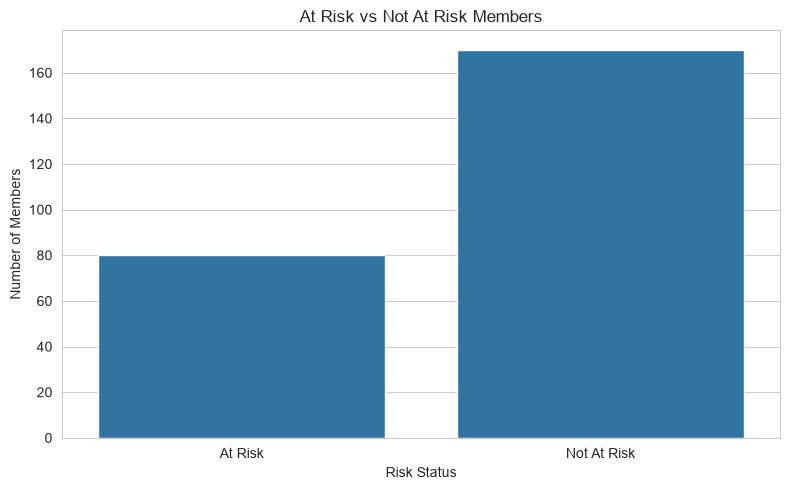

In [24]:
# Q4: Risk Status Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Risk_Status"
)

plt.title("At Risk vs Not At Risk Members")

plt.xlabel("Risk Status")

plt.ylabel("Number of Members")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q4_risk_distribution.png",
    dpi=300
)

plt.show()

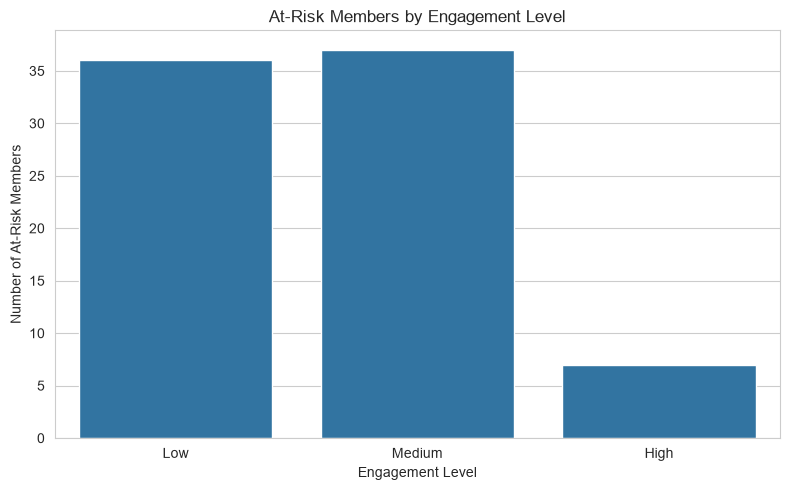

In [25]:
# Q4: Engagement Level of At-Risk Members

plt.figure(figsize=(8, 5))

sns.countplot(
    data=at_risk_members,
    x="Engagement_Level",
    order=["Low", "Medium", "High"]
)

plt.title("At-Risk Members by Engagement Level")

plt.xlabel("Engagement Level")

plt.ylabel("Number of At-Risk Members")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images/q4_risk_by_engagement.png",
    dpi=300
)

plt.show()